# AP 155 Lab Exercise
---
## Exercise 10: Fourier transform

_Instructions_:
- **Report**: See instructions in Problems 1,2,3
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Ricerra, Myke Lawrence
- _Student No._: 2024-07203
- _Section_: THU-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness  | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_

---
## Section 1: Report

### Report figure

<img src="figures/10.1.png" alt="Time and Frequency Representations of Gaussian and Square Wave Signals" width=60%>

**Figure 1. Time and Frequency Representations of Gaussian and Square Wave Signals.** Comparison of Gaussian ($\sigma = 0.25, 1, 4$) and square waves (single pulse vs. periodic wave) alongside their Fourier transform magnitudes and phases.

<img src="figures/10.2.png" alt="Original vs. Filtered/Recovered Composite Signal" width=60%>

**Figure 2. Original vs. Filtered/Recovered Composite Signal.** Time-domain comparison between the original composite signal and the signal recovered after FFT frequency-threshold filtering.

<img src="figures/10.3.png" alt="Sampling Effects and Aliasing of a 50Hz Sinusoid" width=60%>

**Figure 3. Sampling Effects and Aliasing of a $50\text{ Hz}$ Sinusoid.**  Time-domain sampling and FT magnitude comparison of a $50\text{ Hz}$ wave sampled at $500\text{ Hz}$ (non-aliased) versus $60\text{ Hz}$ (aliased).

### Report discussion

Problem 1:
Changing the shape or width of an input signal inversely scales its Fourier transform spread in frequency. The narrower the signal is in the time domain, the wider it is in the frequency domain, and vice versa (this is easily visualized with the Gaussian function, as seen in Figure 1). Additionally, features such as symmetry, periodicity, and sharp edges govern the phase behavior and spectral structure (such as discrete harmonic lines or sinc-like envelopes for square waves).

Problem 2:
Lowering $N$ at fixed $\Delta t$ shortens the observation window $T = N\Delta t$ and lowers the frequency resolution $\Delta f = 1/(N\Delta t)$, while keeping $f_{\max} = 1/(2\Delta t)$. Signal recovery remains possible as long as the true peaks stay well above the noise floor. Once $N$ becomes too small—making $\Delta f$ too coarse to resolve nearby frequencies (such as 130 Hz, 180 Hz, and 230 Hz) or letting leakage and noise mask the peaks—recovery degrades noticeably.

Problem 3: Sampling below the Nyquist rate turns high frequencies into lower apparent ones, as seen in Figure 3 for a $50\text{ Hz}$ actual wave. At $f_s = 500\text{ Hz}$ ($f_s > 2f_{\text{sig}}$), the signal and its $50\text{ Hz}$ signal are preserved, whereas at $f_s = 60\text{ Hz}$ ($f_s < 2f_{\text{sig}}$), aliasing produces an apparent $10\text{ Hz}$ signal.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy import signal

### Problem 1: Exploring FT of varying waveforms

Given the waveforms from the pool below, produce a $1\times3$ plot containing the following:
1) the signal, with its variations,
2) the magnitude of its Fourier transform, and
3) the phase information of the transform (up to you if unwrapped or not).
    
Discussion: 2-3 sentences explaining how changing the shape of the input signal affects it transform.
Ex: for the Gaussian waveform, how does it Fourier transform change based on increasing or decreasing sigma?

Waveforms you can try (prefarably non-sinusoidal):
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function (vary sigma)
- Finite-time sinusoid
- Gaussian wave packet
- Dirac-delta

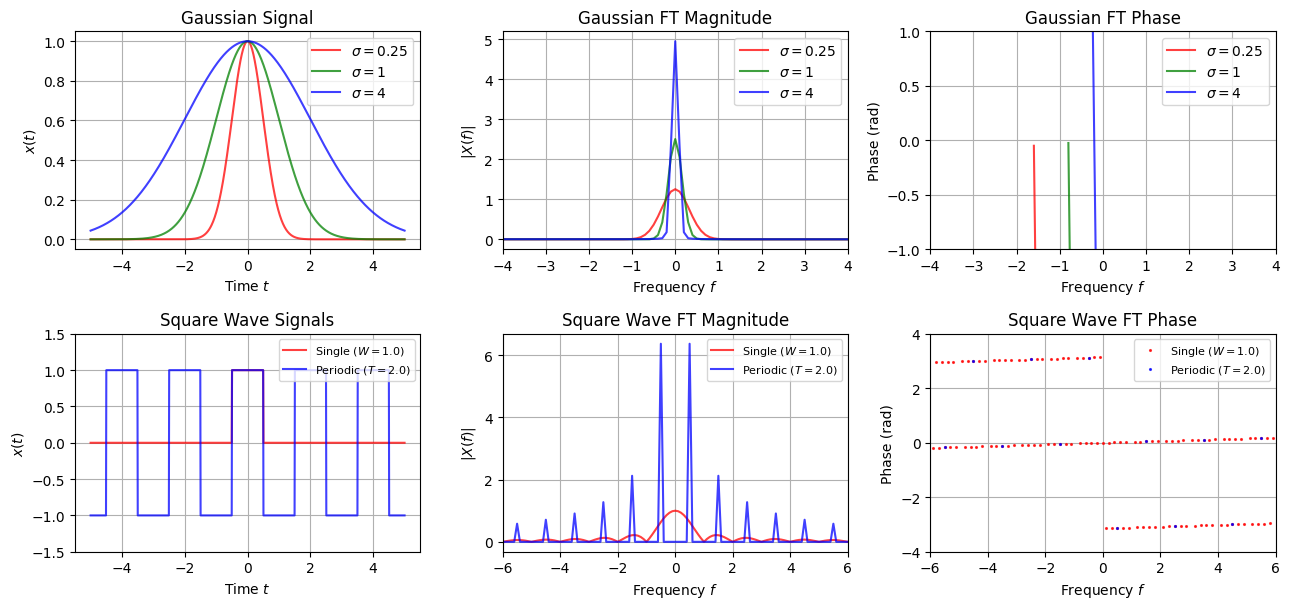

In [2]:
#I tried Gaussian function and Square wave

N = 1000
t = np.linspace(-5,5,N)

deltaT = t[1] - t[0]
freqs = np.fft.fftshift(np.fft.fftfreq(N, deltaT))

fig, axs = plt.subplots(2, 3, figsize=(13, 6.2))

# Gaussian function
ax_t1, ax_f1, ax_p1 = axs[0]

sigmas = [0.25, 1, 4]
colors = ["red", "green", "blue"]

for s, c in zip(sigmas, colors):
  x = np.exp(-0.5 * t**2 / s)

  Xk = np.fft.fftshift(np.fft.fft(x)) * deltaT
  Xk_mag = np.abs(Xk)

  Xk_phase = np.unwrap(np.angle(Xk))
  Xk_phase_clean = np.where(Xk_mag > 1e-6 * np.max(Xk_mag), Xk_phase, np.nan)

  ax_t1.plot(t, x, label=fr"$\sigma = {s}$", color=c, alpha=0.75)
  ax_f1.plot(freqs, Xk_mag, label=fr"$\sigma = {s}$", color=c, alpha=0.75)
  ax_p1.plot(freqs, Xk_phase_clean, label=fr"$\sigma = {s}$", color=c, alpha=0.75)

ax_t1.set_title("Gaussian Signal")
ax_t1.set_xlabel("Time $t$")
ax_t1.set_ylabel("$x(t)$")
ax_t1.legend()

ax_f1.set_title("Gaussian FT Magnitude")
ax_f1.set_xlabel("Frequency $f$")
ax_f1.set_ylabel("$|X(f)|$")
ax_f1.set_xlim([-4, 4])
ax_f1.legend()

ax_p1.set_title("Gaussian FT Phase")
ax_p1.set_xlabel("Frequency $f$")
ax_p1.set_ylabel("Phase (rad)")
ax_p1.set_xlim([-4, 4])
ax_p1.set_ylim([-1, 1])
ax_p1.legend()

# Square waves (single & periodic)
ax_t2, ax_f2, ax_p2 = axs[1]

square_signals = [
    (fr"Single ($W = 1.0$)", np.where(np.abs(t) <= 0.5, 1.0, 0.0), "red"),
    (fr"Periodic ($T = 2.0$)", signal.square(2 * np.pi * 0.5 * t + np.pi / 2, duty=0.5), "blue"),
]

for label, x_sq, c in square_signals:
  Xk = np.fft.fftshift(np.fft.fft(x_sq)) * deltaT
  Xk_mag = np.abs(Xk)

  Xk_phase = np.angle(Xk)
  Xk_phase_clean = np.where(Xk_mag > 1e-3 * np.max(Xk_mag), Xk_phase, np.nan)

  ax_t2.plot(t, x_sq, label=label, color=c, alpha=0.75)
  ax_f2.plot(freqs, Xk_mag, label=label, color=c, alpha=0.75)
  ax_p2.plot(freqs, Xk_phase_clean, ".", label=label, color=c, alpha=0.75, markersize=2.5)

ax_t2.set_title("Square Wave Signals")
ax_t2.set_xlabel(fr"Time $t$")
ax_t2.set_ylabel(fr"$x(t)$")
ax_t2.set_ylim([-1.5, 1.5])
ax_t2.legend(fontsize=8)

ax_f2.set_title("Square Wave FT Magnitude")
ax_f2.set_xlabel(fr"Frequency $f$")
ax_f2.set_ylabel(fr"$|X(f)|$")
ax_f2.set_xlim([-6, 6])
ax_f2.legend(fontsize=8)

ax_p2.set_title("Square Wave FT Phase")
ax_p2.set_xlabel(fr"Frequency $f$")
ax_p2.set_ylabel("Phase (rad)")
ax_p2.set_xlim([-6, 6])
ax_p2.set_ylim([-4, 4])
ax_p2.legend(fontsize=8)

for ax in axs.flat:
  ax.grid(True)

fig.tight_layout()
plt.show()

### Problem 2: Signal Processing in 1D (Fill in the blanks/Code to get to the desired result)

Steps performed:

1) Create a composite signal from multiple sinusoids with three frequencies, get fft of clean signal
2) Add noise (gaussian noise)
3) Add a window (Hann)
4) Get fft of the noisy signal
5) filter frequencies below a threshold
6) get the inverse fft
7) compare the result

Discussion: Try running the procedure with a lower number of N (N<25000). What does lowering N do to the original signal? Will I still be able to recover that original signal if I add the noise below? Is there a limit of N to which I can recover the signal well? Why? (Answer in ~3 sentences)


In [3]:
#Make a wave (cosine or sine) - you can do combo of waves
N = 25000
dt = 0.0002 #if spacing is 0.0002, then frequency is 5000 Hz
t_ = np.arange(N)*dt
freqs = [130, 230, 180]
phase = [np.pi/3, np.pi/4, np.pi/6]


signal_original = np.sum([np.cos(2*np.pi*f*t_ + p) for f, p in zip(freqs, phase)], axis=0)

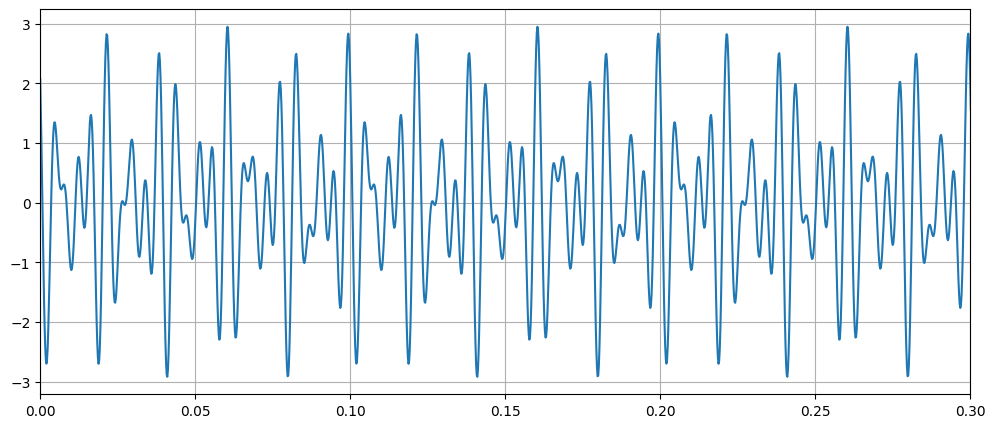

In [4]:
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, signal_original)
ax.set_xlim(0,0.3)
ax.grid(True);

In [5]:
#FILL: Plot the fourier transform of the clean, original signal

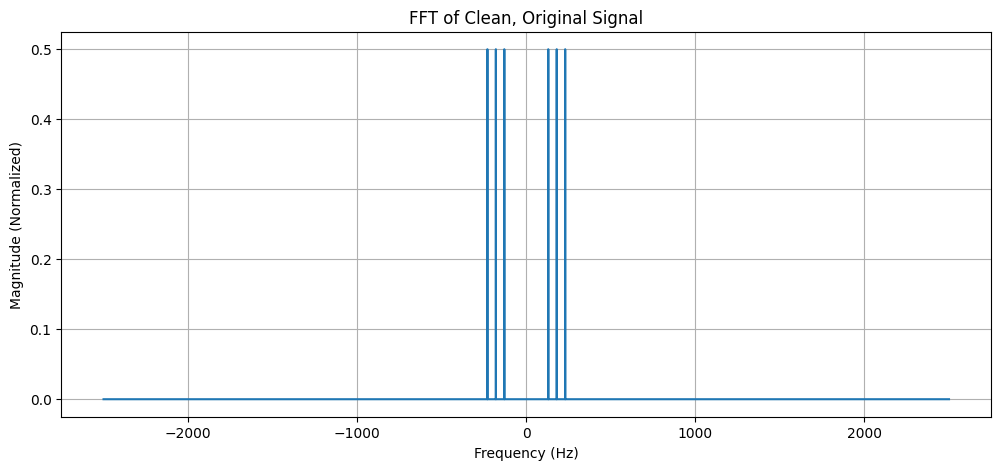

In [6]:
clean_fft = np.fft.fft(signal_original)
clean_freqs = np.fft.fftfreq(N, dt)
clean_mag = np.abs(clean_fft) / N

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(np.fft.fftshift(clean_freqs), np.fft.fftshift(clean_mag))
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Magnitude (Normalized)")
ax.set_title("FFT of Clean, Original Signal")
ax.grid(True);

In [7]:
rng = np.random.default_rng()

#Define parameters of Gaussian noise)
mean = 0
std = 2

noise = rng.normal(loc = mean, scale = std, size = len(t_)) #Add noise to every data point
#Noisy data here
noisy_data = signal_original + noise*5

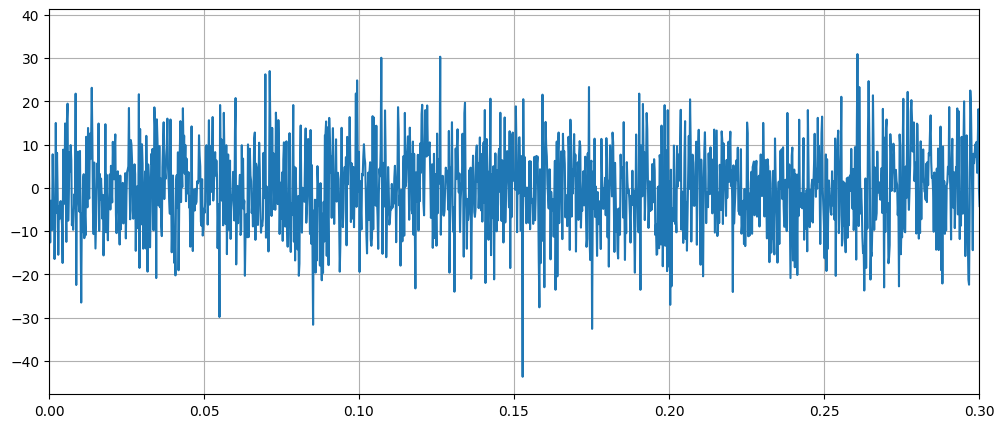

In [8]:
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, noisy_data)
ax.set_xlim(0,0.3)
ax.grid(True);

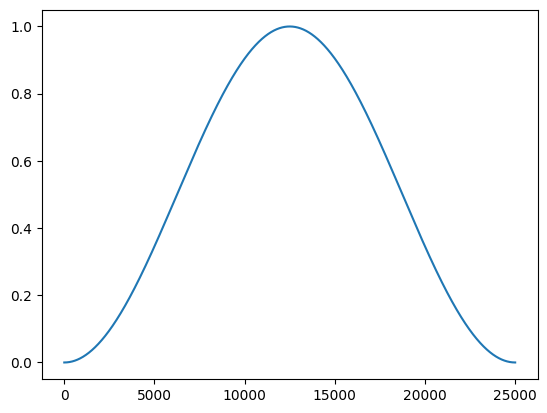

In [9]:
window = np.hanning(len(noisy_data)) #Create a window the size of the data length
plt.plot(window)
ax.grid(True);

In [10]:
#fourier of hanning window
windowSigPeaks = np.abs(np.fft.fftshift(np.fft.fft(window)))
windowSigFreqs = np.fft.fftshift(np.fft.fftfreq(N, dt))


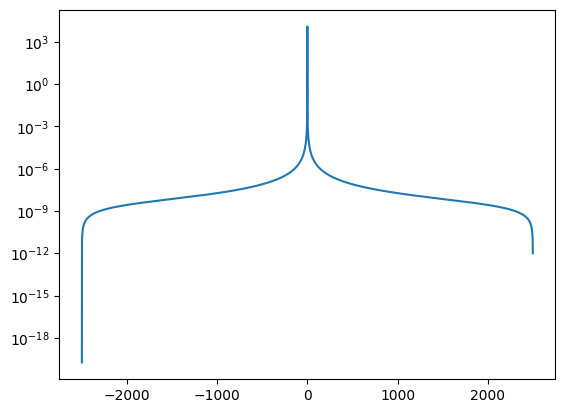

In [11]:
plt.plot(windowSigFreqs, windowSigPeaks)
plt.yscale('log')
ax.grid(True);

In [12]:
noisyFourier = np.fft.fft(noisy_data*window)

noisySigPeaks = np.abs(np.fft.fftshift(noisyFourier))
shiftedFreqs = np.fft.fftshift(np.fft.fftfreq(N, dt))

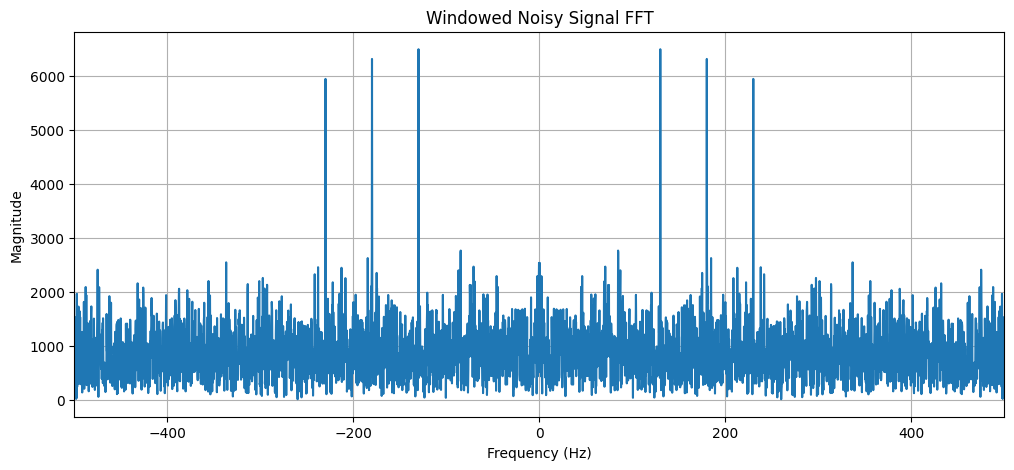

In [13]:
# Fill: Plot the magnitude of fourier transform of the noisy data multiplied by the hanning window

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(shiftedFreqs, noisySigPeaks)
ax.set_xlim(-500, 500)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Magnitude")
ax.set_title("Windowed Noisy Signal FFT")
ax.grid(True);

In [14]:
# Fill: Find a suitable threshold value to filter the noise in fourier space

mag = np.abs(noisyFourier)

noise_floor = np.median(mag)
p99 = np.percentile(mag, 99)
top_peaks = np.sort(mag)[-6:]  # top 6 based from above
min_signal_peak = np.min(top_peaks)

threshold = 0.5 * (p99 + min_signal_peak)
cleanedFourier = np.where(np.abs(noisyFourier) > threshold, noisyFourier, 0)

In [15]:
# Fill: with the cleaned signal in fourier space, convert it back to the time domain

window_gain = np.mean(window)
recoveredSignal = np.real(np.fft.ifft(cleanedFourier)) / window_gain

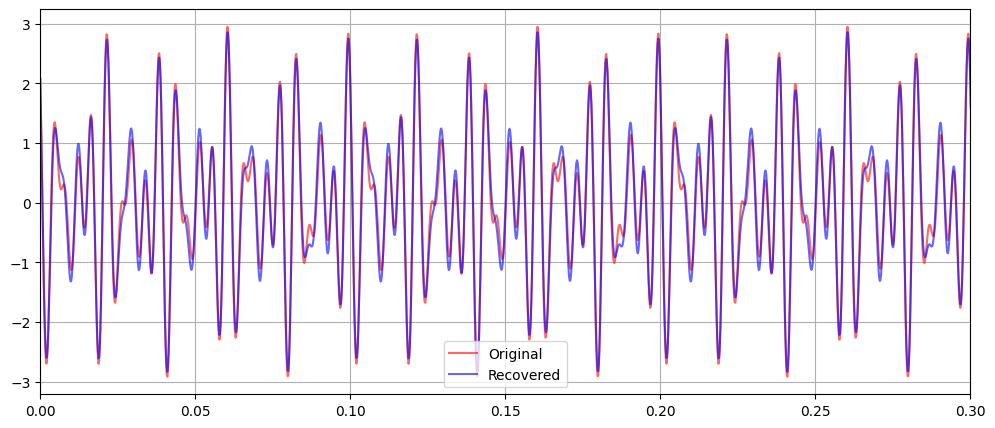

In [16]:
# Plot the recovered signal

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(t_, signal_original, label="Original", alpha=0.6, color="red")
ax.plot(t_, recoveredSignal, label="Recovered", alpha=0.6, color="blue")
ax.set_xlim(0, 0.3)
ax.legend()
ax.grid(True);

### Problem 3: Aliasing
1) Using different sampling frequencies (uniform sampling), generate a sinusoidal signal. Note the sampling frequencies, and the signal frequency. Use a sampling frequency above the Nyquist frequency, and another one below it.
3) Get their fourier transforms. Are they the same?
4) Plot: Show the fourier transform of an aliased signal, how it looks like in the time-domain, and how the actual signal looks like in the time domain if it's not aliased.
   
Discussion: Explain the report figure. Note the frequency of the signal you wanted to sample, the sampling frequencies used for the aliased and the non-aliased wave

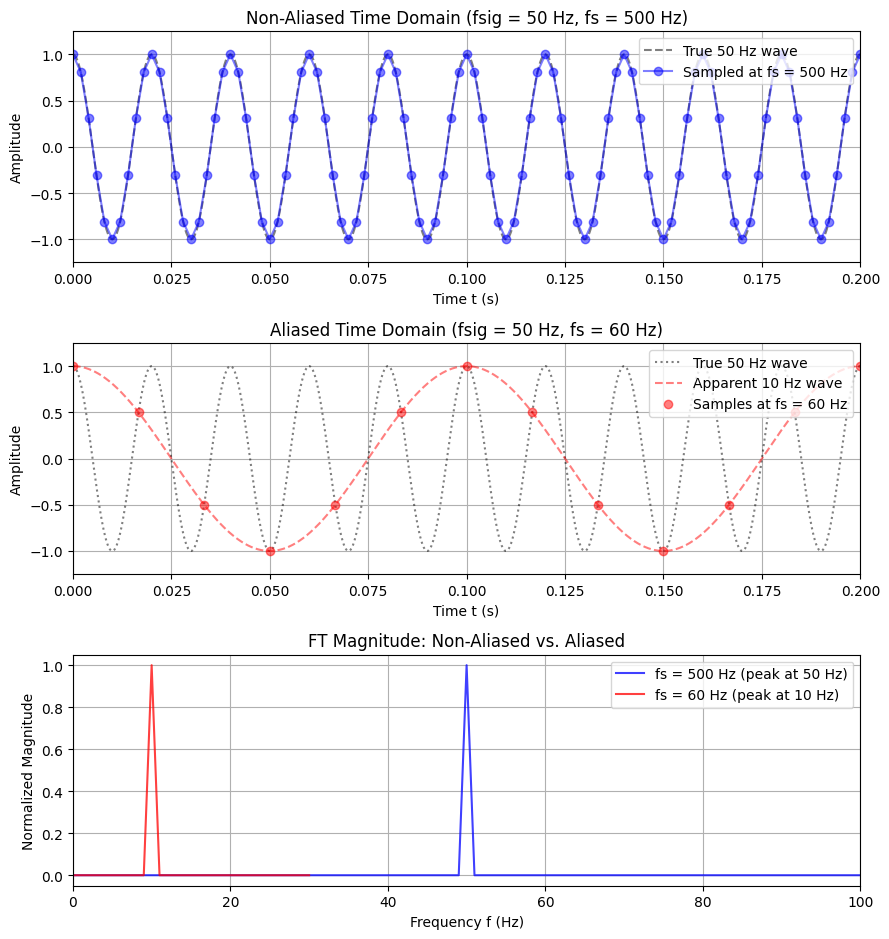

In [17]:
f_sig = 50.0
fs_high = 500.0
fs_low = 60.0
T = 1.0

# Non-aliased sampling (fs_high = 500 Hz)
N_high = int(fs_high * T)
t_high = np.arange(N_high) / fs_high
x_high = np.cos(2 * np.pi * f_sig * t_high)

freqs_high = np.fft.rfftfreq(N_high, d=1 / fs_high)
mag_high = np.abs(np.fft.rfft(x_high)) / (N_high / 2)

# Aliased sampling (fs_low = 60 Hz)
N_low = int(fs_low * T)
t_low = np.arange(N_low) / fs_low
x_low = np.cos(2 * np.pi * f_sig * t_low)

freqs_low = np.fft.rfftfreq(N_low, d=1 / fs_low)
mag_low = np.abs(np.fft.rfft(x_low)) / (N_low / 2)

#True 50 Hz
t_cont = np.linspace(0, 0.20, 4000)
x_cont = np.cos(2 * np.pi * f_sig * t_cont)

x_alias_apparent = np.cos(2 * np.pi * 10.0 * t_cont)

fig, axes = plt.subplots(3, 1, figsize=(9, 9.5))

# Non-aliased time domain
axes[0].plot(t_cont, x_cont, "--", color="black", alpha = 0.5, label="True 50 Hz wave")
axes[0].plot(t_high, x_high, "o-", color="blue", alpha = 0.5, label="Sampled at fs = 500 Hz")
axes[0].set_title("Non-Aliased Time Domain (fsig = 50 Hz, fs = 500 Hz)")
axes[0].set_xlabel("Time t (s)")
axes[0].set_ylabel("Amplitude")
axes[0].set_xlim(0, 0.20)
axes[0].set_ylim(-1.25, 1.25)
axes[0].grid(True)
axes[0].legend(loc="upper right")

# Aliased time domain
axes[1].plot(t_cont, x_cont, ":", color="black", alpha=0.5, label="True 50 Hz wave")
axes[1].plot(t_cont, x_alias_apparent, "--", color="red", alpha=0.5, label="Apparent 10 Hz wave")
axes[1].plot(t_low, x_low, "o", color="red", alpha=0.5, label="Samples at fs = 60 Hz")
axes[1].set_title("Aliased Time Domain (fsig = 50 Hz, fs = 60 Hz)")
axes[1].set_xlabel("Time t (s)")
axes[1].set_ylabel("Amplitude")
axes[1].set_xlim(0, 0.20)
axes[1].set_ylim(-1.25, 1.25)
axes[1].grid(True)
axes[1].legend(loc="upper right")

# Magnitude Fourier transforms
axes[2].plot(freqs_high, mag_high, color="blue", alpha=0.75, label="fs = 500 Hz (peak at 50 Hz)")
axes[2].plot(freqs_low, mag_low , color="red", alpha=0.75, label="fs = 60 Hz (peak at 10 Hz)")
axes[2].set_title("FT Magnitude: Non-Aliased vs. Aliased")
axes[2].set_xlabel("Frequency f (Hz)")
axes[2].set_ylabel("Normalized Magnitude")
axes[2].set_xlim(0, 100)
axes[2].grid(True)
axes[2].legend(loc="upper right")

plt.tight_layout()

#### Problem code summary

The entire activity uses the np.fft library to analyze the given signals and compute their Fourier transforms. In Problem 3, the Fourier transform is used to identify the significant frequency components, which are then filtered using a threshold to recover the original signal.

---
## Section 3: Notes

In [18]:
import numpy as np
import matplotlib.pyplot as plt

### Fourier transform (from $t$-space to $\omega$-space)
$$ Y(\omega) = \int_{-\infty}^{+\infty} dt \frac{e^{-i\omega t}}{\sqrt{2\pi}}y(t)$$

### Inverse Fourier transform (from $\omega$-space to $t$-space)
$$ y(t) = \int_{-\infty}^{+\infty} d\omega Y(\omega) \frac{e^{i\omega t}}{\sqrt{2\pi}}$$

Something to think about: while we essentially do numerical integration, we do not impose h. Instead, we utilize the spacing of the dataset.

### Discrete FT/IFT

$$ Y_n = \frac{1}{\sqrt{2\pi}} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{y_k\}  +\sin(nk\theta)\Im\{y_k\} +i(\cos(nk\theta)\Im\{y_k\} −\sin(nk\theta)\Re\{y_k\})]\right]$$

$$ y_k = \frac{\sqrt{2\pi}}{N} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{Y_n\}  -\sin(nk\theta)\Im\{Y_n\} +i(\cos(nk\theta)\Im\{Y_n\} +\sin(nk\theta)\Re\{Y_n\})]\right]$$

Why bother it doing this way?

It cleanly splits the real and imaginary part for both inputs and outputs, so that you can use a pair of floats rather than an aggregate complex data type (complex128 is just a pair of float64 anyway).

Using $Z=e^{−i\theta}, \rightarrow Z^{\pm nk} = e^{\mp ink\theta} = \cos(nk\theta)\mp i\sin(nk\theta)$.

(0.0, 4.0)

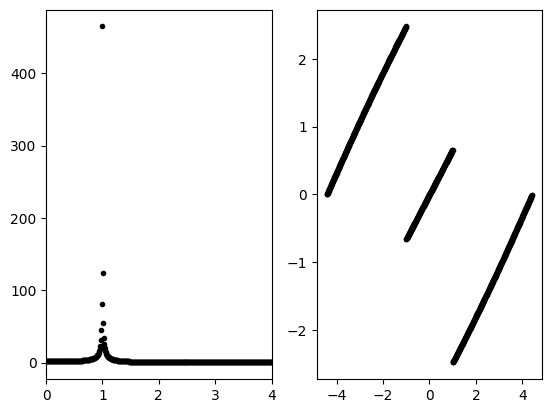

In [19]:
import numpy as np
import matplotlib.pyplot as plt

N = 1000
x = np.linspace(0, 18*2*np.pi, N)
deltaT = x[1] - x[0]

f = 1
y = np.cos(2*np.pi*f*x)

freqs = np.fft.fftfreq(N, deltaT)
Yk = np.fft.fft(y)

# # Q: Why do fftshift?
# Yk = np.fft.fftshift(Yk)

Yk_mag = np.abs(Yk)
Yk_phase = np.angle(Yk)
# Q: Why unwrap?
Yk_phase = np.unwrap(Yk_phase)

fig, ax = plt.subplots(1,2)

ax[0].plot(freqs, Yk_mag, "k.")
ax[1].plot(freqs, Yk_phase, "k.")
ax[0].set_xlim(0, 4)

### Waveforms of interest
- Sinusoid (single frequency, varying phase shift)
- Sum of sinusoids with different frequencies and phases
- Product of sinusoids with different frequencies and phases
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function
- Finite-time sinusoid
- Gaussian wave packet

In [20]:
t = np.linspace(0,10,1000) #Create 100 pts from 0 to 10
x = np.sin(2*np.pi*2*t)

Text(0, 0.5, 'x')

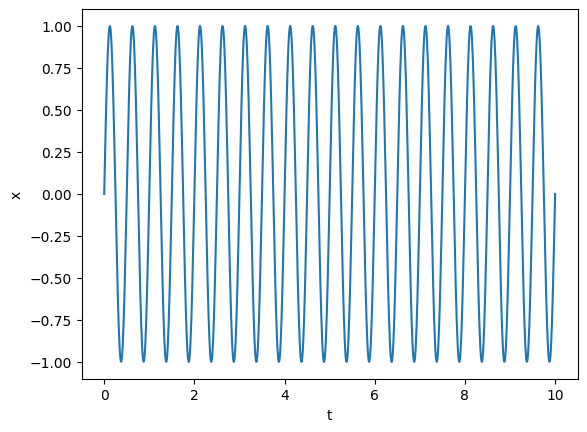

In [21]:
plt.plot(t,x)
plt.xlabel("t")
plt.ylabel("x")

In [22]:
x_ft = np.fft.fft(x)
np.fft.fftfreq?

### Plotting

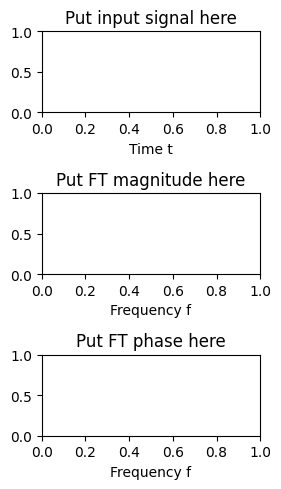

In [23]:
fig, ax = plt.subplots(3, 1, figsize=(3, 5))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

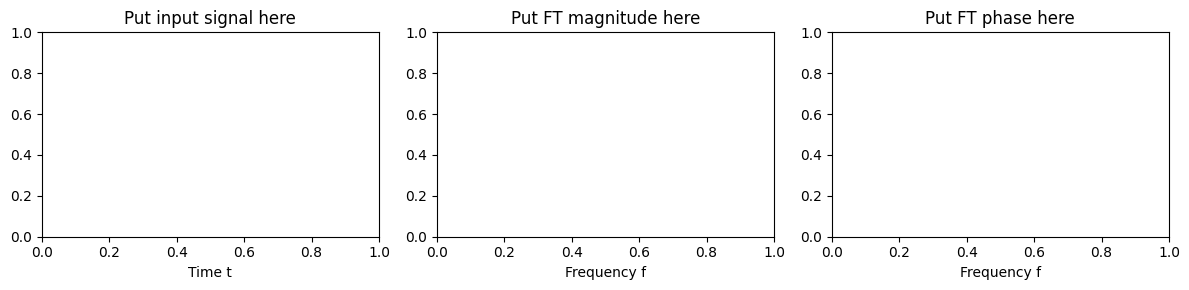

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

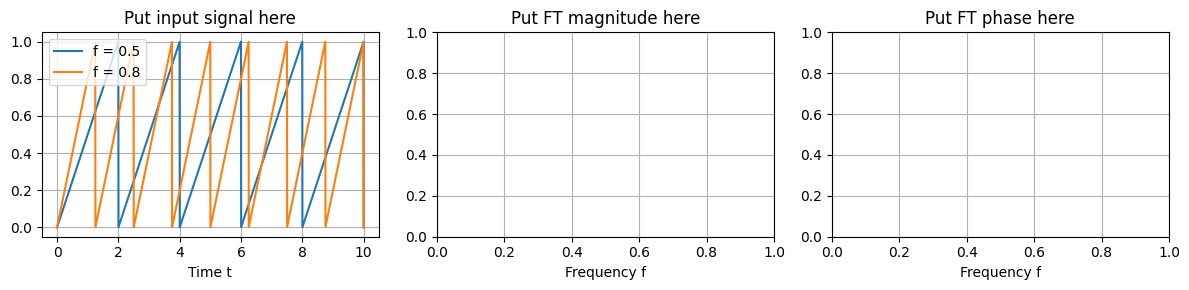

In [25]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
ax_t, ax_f, ax_p = axs

t = np.linspace(0, 10, 2048)
f = 0.5 # Frequency
T = 1/(f) # Period
f2 = 0.8 # Frequency
T2 = 1/(f2) # Period


ax_t.set_title("Put input signal here")
ax_t.set_xlabel("Time t")
ax_t.plot(t, (t%T)/T, label="f = 0.5")
ax_t.plot(t, (t%T2)/T2, label="f = 0.8")
ax_t.legend()
#....
ax_f.set_title("Put FT magnitude here")
ax_f.set_xlabel("Frequency f")
#....
ax_p.set_title("Put FT phase here")
ax_p.set_xlabel("Frequency f")
#...


for ax in axs:
    ax.grid(True)
fig.tight_layout()

## 1-D convolution

In [26]:
a = [1,1,1,0,0,0,0,1,1,1,0,0,0,1,0,0,0,1,1,1,0,1,1,0,0,0,0]
v = [1,1,1]



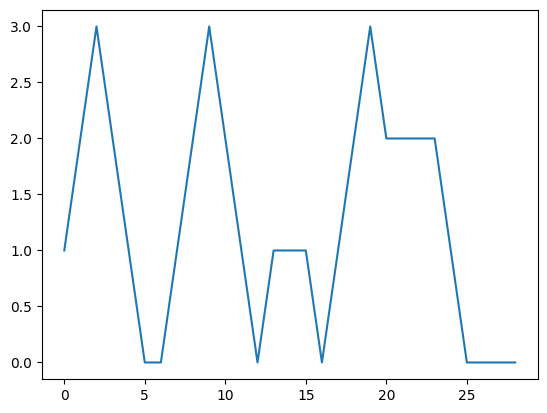

In [27]:
plt.plot(np.arange(len(np.convolve(a,v, mode='full'))), np.convolve(a,v, mode='full'))

### Convolution attempt (bringing circuits analogy)

In [28]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
N = 500
t = np.linspace(0, 1, N, endpoint=False)
t_input = np.linspace(0, 5, N*5, endpoint=False)
signal_freq = 5
# dt = t[1] - t[0]
# nonsinu_signal = signal.square(2 * np.pi * signal_freq * t)

In [29]:
tau = 0.1
h_t = np.exp(-t/tau)
input_signal = signal.square(2 * np.pi * signal_freq * t_input) #cont_signal(t, freq)

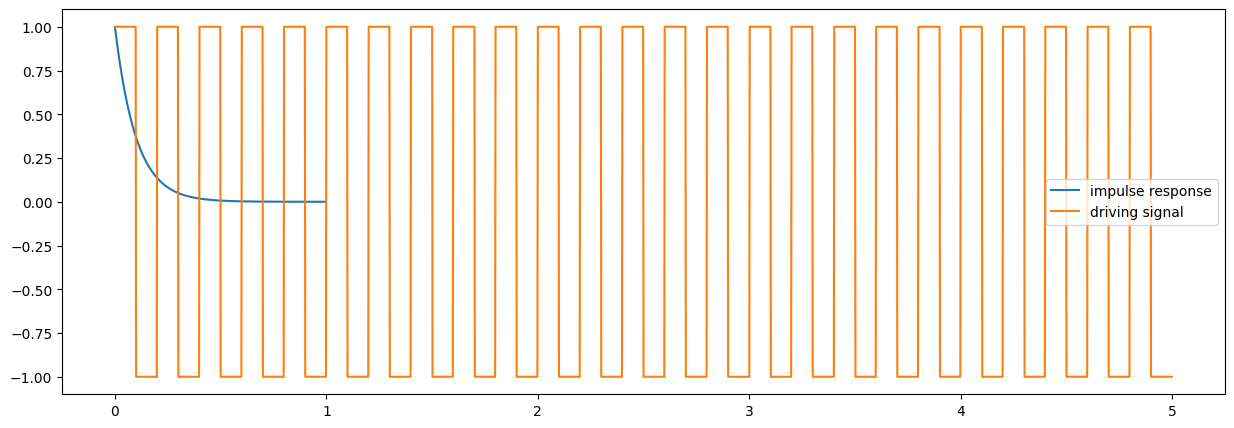

In [30]:
fig, ax = plt.subplots(figsize = (15,5))
ax.plot(t, h_t, label = "impulse response")
ax.plot(t_input, input_signal, label= "driving signal")
ax.legend()

In [31]:
response = np.convolve(input_signal, h_t, mode = "same")

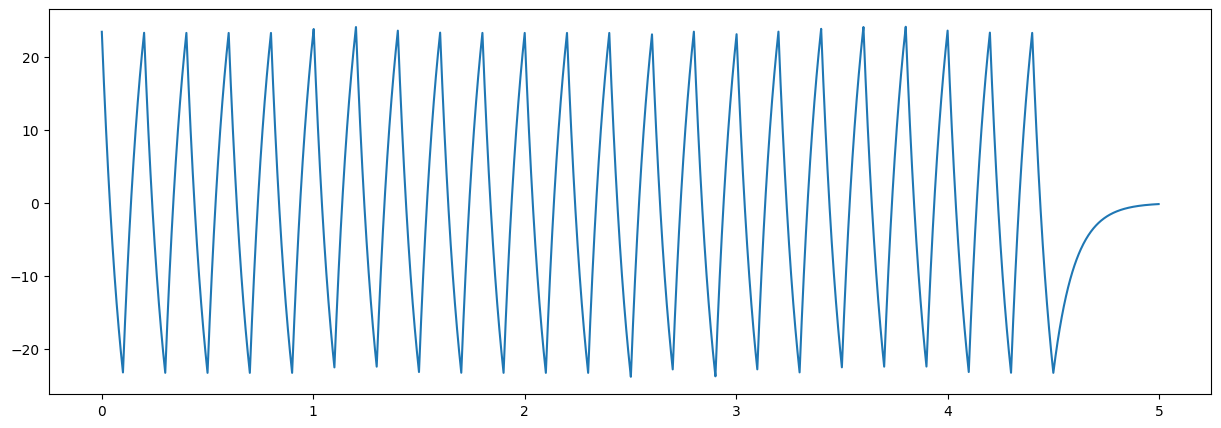

In [32]:
fig, ax = plt.subplots(figsize = (15,5))
#ax.plot(t, input_signal)
ax.plot(t_input, response)

In [33]:
fourier_length = len(h_t) + len(input_signal) - 1

In [34]:
fourier_input = np.fft.fft(input_signal, n = fourier_length)
fourier_h = np.fft.fft(h_t, n = fourier_length)

In [35]:
fourier_response = fourier_h*fourier_input

In [36]:
response = np.real(np.fft.ifft(fourier_response))

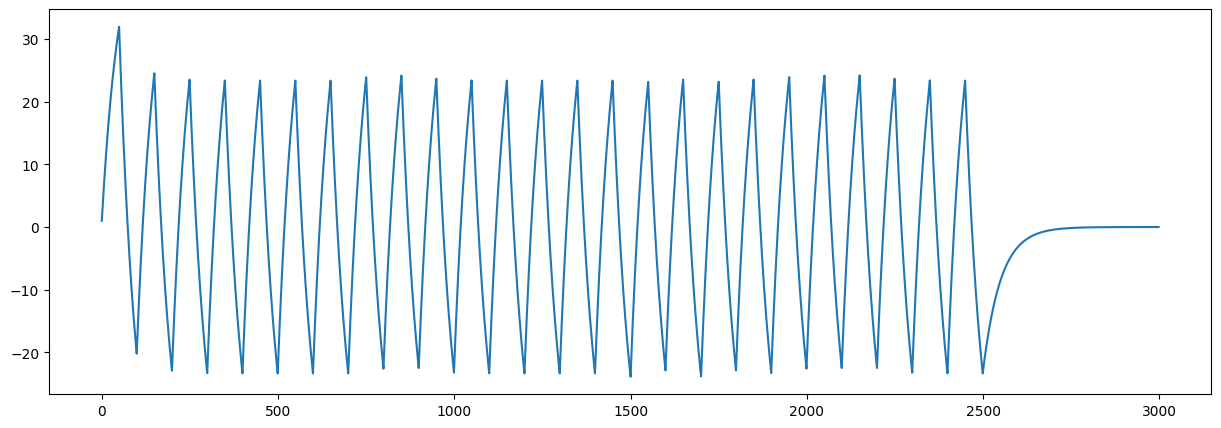

In [37]:
fig, ax = plt.subplots(figsize = (15,5))

ax.plot(response)